## Problem 11: Forecasting U.S. Inflation Using Macroeconomic Indicators with LASSO

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [4]:
series = [
    "CPIAUCSL",
    "UNRATE",
    "FEDFUNDS",
    "INDPRO",
    "M2SL",
    "MCOILWTICO",
    "GS10",
    "GS2",
    "HOUST"
]

df = pd.DataFrame()

for series_id in series:

    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"

    temp = pd.read_csv(url)

    # Rename the first column to DATE
    temp = temp.rename(
        columns={temp.columns[0]: "DATE"}
    )

    # Convert DATE to datetime
    temp["DATE"] = pd.to_datetime(
        temp["DATE"]
    )

    # Make DATE the index
    temp = temp.set_index("DATE")

    if df.empty:
        df = temp
    else:
        df = df.join(
            temp,
            how="outer"
        )

df = df.loc[
    "1986-01-01":"2026-07-01"
]

df.head()

,CPIAUCSL,UNRATE,FEDFUNDS,INDPRO,M2SL,MCOILWTICO,GS10,GS2,HOUST
DATE,,,,,,,,,
1986-01-01,109.9,6.7,8.14,55.7481,2501.6,22.93,9.19,8.14,1972.0
1986-02-01,109.7,7.2,7.86,55.3568,2512.5,15.46,8.70,7.97,1848.0
1986-03-01,109.1,7.2,7.48,54.9625,2533.1,12.61,7.78,7.21,1876.0
1986-04-01,108.7,7.1,6.99,55.0413,2558.1,12.84,7.30,6.70,1933.0
1986-05-01,109.0,7.2,6.85,55.1226,2585.7,15.38,7.71,7.07,1854.0


The dataset begins in 1986 mainly because our oil-price series has suitable observations from around this period.

In [5]:
df = df.resample("MS").mean()

df.head()

,CPIAUCSL,UNRATE,FEDFUNDS,INDPRO,M2SL,MCOILWTICO,GS10,GS2,HOUST
DATE,,,,,,,,,
1986-01-01,109.9,6.7,8.14,55.7481,2501.6,22.93,9.19,8.14,1972.0
1986-02-01,109.7,7.2,7.86,55.3568,2512.5,15.46,8.70,7.97,1848.0
1986-03-01,109.1,7.2,7.48,54.9625,2533.1,12.61,7.78,7.21,1876.0
1986-04-01,108.7,7.1,6.99,55.0413,2558.1,12.84,7.30,6.70,1933.0
1986-05-01,109.0,7.2,6.85,55.1226,2585.7,15.38,7.71,7.07,1854.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 487 entries, 1986-01-01 to 2026-07-01
Freq: MS
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CPIAUCSL    486 non-null    float64
 1   UNRATE      486 non-null    float64
 2   FEDFUNDS    487 non-null    float64
 3   INDPRO      487 non-null    float64
 4   M2SL        486 non-null    float64
 5   MCOILWTICO  487 non-null    float64
 6   GS10        487 non-null    float64
 7   GS2         487 non-null    float64
 8   HOUST       487 non-null    float64
dtypes: float64(9)
memory usage: 38.0 KB


In [7]:
df.describe()

,CPIAUCSL,UNRATE,FEDFUNDS,INDPRO,M2SL,MCOILWTICO,GS10,GS2,HOUST
count,486.000000,486.000000,487.000000,487.000000,486.000000,487.000000,487.000000,487.000000,487.000000
mean,202.489947,5.687037,3.351663,87.427105,9037.194444,48.599466,4.656468,3.693511,1350.987680
std,58.125405,1.666349,2.637355,15.406418,6192.868411,29.487472,2.209317,2.538679,368.242115
min,108.700000,3.400000,0.050000,54.900500,2501.600000,11.350000,0.620000,0.120000,478.000000
25%,155.125000,4.400000,0.475000,73.630100,3666.950000,20.280000,2.815000,1.210000,1146.000000
50%,200.200000,5.400000,3.300000,92.949900,6786.600000,44.650000,4.360000,3.890000,1382.000000
75%,239.415750,6.600000,5.330000,100.160450,12786.000000,71.615000,6.265000,5.700000,1588.500000
max,333.979000,14.800000,9.850000,104.100400,23155.200000,133.880000,9.520000,9.680000,2273.000000


In [8]:
df.isna().sum()

CPIAUCSL      1
UNRATE        1
FEDFUNDS      0
INDPRO        0
M2SL          1
MCOILWTICO    0
GS10          0
GS2           0
HOUST         0
dtype: int64

In [9]:
df = df.rename(columns={
    "CPIAUCSL": "cpi",
    "UNRATE": "unemployment",
    "FEDFUNDS": "fed_funds",
    "INDPRO": "industrial_production",
    "M2SL": "money_supply",
    "MCOILWTICO": "oil_price",
    "GS10": "treasury_10y",
    "GS2": "treasury_2y",
    "HOUST": "housing_starts"
})

df.head()

,cpi,unemployment,fed_funds,industrial_production,money_supply,oil_price,treasury_10y,treasury_2y,housing_starts
DATE,,,,,,,,,
1986-01-01,109.9,6.7,8.14,55.7481,2501.6,22.93,9.19,8.14,1972.0
1986-02-01,109.7,7.2,7.86,55.3568,2512.5,15.46,8.70,7.97,1848.0
1986-03-01,109.1,7.2,7.48,54.9625,2533.1,12.61,7.78,7.21,1876.0
1986-04-01,108.7,7.1,6.99,55.0413,2558.1,12.84,7.30,6.70,1933.0
1986-05-01,109.0,7.2,6.85,55.1226,2585.7,15.38,7.71,7.07,1854.0


In [10]:
# This calculates approximately the percentage change in prices over the previous twelve months.

df["current_inflation"] = (
    100 *
    (
        np.log(df["cpi"])
        - np.log(df["cpi"].shift(12))
    )
)

**Construct Future Inflation**

In [11]:
df["future_inflation"] = (
    100 *
    (
        np.log(df["cpi"].shift(-12))
        - np.log(df["cpi"])
    )
)

In [12]:
df["industrial_growth"] = (
    100 *
    (
        np.log(df["industrial_production"])
        - np.log(df["industrial_production"].shift(12))
    )
)

df["money_growth"] = (
    100 *
    (
        np.log(df["money_supply"])
        - np.log(df["money_supply"].shift(12))
    )
)

df["oil_growth"] = (
    100 *
    (
        np.log(df["oil_price"])
        - np.log(df["oil_price"].shift(12))
    )
)

df["housing_growth"] = (
    100 *
    (
        np.log(df["housing_starts"])
        - np.log(df["housing_starts"].shift(12))
    )
)

df["term_spread"] = (
    df["treasury_10y"]
    - df["treasury_2y"]
)

**Create the Final Modelling Dataset**

In [13]:
model_df = df[[
    "current_inflation",
    "unemployment",
    "fed_funds",
    "industrial_growth",
    "money_growth",
    "oil_growth",
    "term_spread",
    "housing_growth",
    "future_inflation"
]].copy()

model_df = model_df.dropna()

model_df.head()

,current_inflation,unemployment,fed_funds,industrial_growth,money_growth,oil_growth,term_spread,housing_growth,future_inflation
DATE,,,,,,,,,
1987-01-01,1.355647,6.6,6.43,0.608212,9.223105,-20.659995,0.85,-10.581137,4.046286
1987-02-01,1.896219,6.6,6.10,2.622086,8.923113,13.812947,0.85,-3.524594,3.860128
1987-03-01,2.801810,6.6,6.13,3.481642,8.342898,37.241091,0.83,-8.333526,3.760828
1987-04-01,3.613763,6.3,6.37,3.969486,7.878799,37.488813,1.00,-18.035763,3.915246
1987-05-01,3.603994,6.3,6.85,4.452164,7.018590,23.426483,0.85,-12.999320,3.905051


In [14]:
model_df.shape

(462, 9)

In [15]:
model_df["future_inflation"].describe()

count    462.000000
mean       2.749879
std        1.543046
min       -1.978199
25%        1.780001
50%        2.651154
75%        3.384224
max        8.598833
Name: future_inflation, dtype: float64

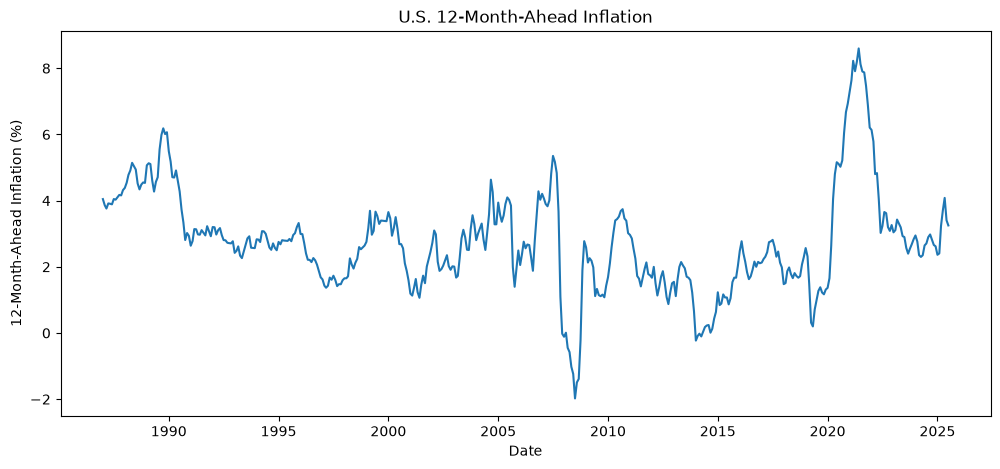

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(
    model_df.index,
    model_df["future_inflation"]
)

plt.xlabel("Date")
plt.ylabel("12-Month-Ahead Inflation (%)")
plt.title("U.S. 12-Month-Ahead Inflation")

plt.show()

**Examine Correlations**

In [22]:
correlations = model_df.corr()

correlations.round(2)

,current_inflation,unemployment,fed_funds,industrial_growth,money_growth,oil_growth,term_spread,housing_growth,future_inflation
current_inflation,1.00,-0.33,0.43,0.30,-0.21,0.56,-0.35,-0.09,0.35
unemployment,-0.33,1.00,-0.39,-0.25,0.25,-0.17,0.70,-0.00,-0.03
fed_funds,0.43,-0.39,1.00,0.28,-0.36,0.09,-0.61,-0.25,0.27
industrial_growth,0.30,-0.25,0.28,1.00,-0.30,0.48,-0.11,0.42,0.15
money_growth,-0.21,0.25,-0.36,-0.30,1.00,-0.04,0.15,0.06,0.28
oil_growth,0.56,-0.17,0.09,0.48,-0.04,1.00,-0.04,0.10,0.18
term_spread,-0.35,0.70,-0.61,-0.11,0.15,-0.04,1.00,0.14,-0.25
housing_growth,-0.09,-0.00,-0.25,0.42,0.06,0.10,0.14,1.00,0.04
future_inflation,0.35,-0.03,0.27,0.15,0.28,0.18,-0.25,0.04,1.00


In [23]:
correlations["future_inflation"].sort_values(
    ascending=False
)

future_inflation     1.000000
current_inflation    0.346518
money_growth         0.282185
fed_funds            0.267751
oil_growth           0.181600
industrial_growth    0.147180
housing_growth       0.036635
unemployment        -0.032636
term_spread         -0.247812
Name: future_inflation, dtype: float64

**Define X and y**

In [24]:
features = [
    "current_inflation",
    "unemployment",
    "fed_funds",
    "industrial_growth",
    "money_growth",
    "oil_growth",
    "term_spread",
    "housing_growth"
]

X = model_df[features]

y = model_df["future_inflation"]

In [25]:
X.head()

,current_inflation,unemployment,fed_funds,industrial_growth,money_growth,oil_growth,term_spread,housing_growth
DATE,,,,,,,,
1987-01-01,1.355647,6.6,6.43,0.608212,9.223105,-20.659995,0.85,-10.581137
1987-02-01,1.896219,6.6,6.10,2.622086,8.923113,13.812947,0.85,-3.524594
1987-03-01,2.801810,6.6,6.13,3.481642,8.342898,37.241091,0.83,-8.333526
1987-04-01,3.613763,6.3,6.37,3.969486,7.878799,37.488813,1.00,-18.035763
1987-05-01,3.603994,6.3,6.85,4.452164,7.018590,23.426483,0.85,-12.999320


In [26]:
y.head()

DATE
1987-01-01    4.046286
1987-02-01    3.860128
1987-03-01    3.760828
1987-04-01    3.915246
1987-05-01    3.905051
Name: future_inflation, dtype: float64

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,shuffle=False)
X_train = X_train.iloc[:-12]
y_train = y_train.iloc[:-12]

shuffle=False keeps the original chronological order.

In [29]:
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

print()

print("Training period:")
print(X_train.index.min(), "to", X_train.index.max())

print()

print("Test period:")
print(X_test.index.min(), "to", X_test.index.max())

Training observations: 357
Test observations: 93

Training period:
1987-01-01 00:00:00 to 2016-09-01 00:00:00

Test period:
2017-10-01 00:00:00 to 2025-07-01 00:00:00


In [30]:
X_train.describe().round(2)

,current_inflation,unemployment,fed_funds,industrial_growth,money_growth,oil_growth,term_spread,housing_growth
count,357.00,357.00,357.00,357.00,357.00,357.00,357.00,357.00
mean,2.62,6.02,3.55,1.95,5.31,3.41,1.17,-1.53
std,1.34,1.48,2.75,4.07,2.17,31.81,0.89,19.33
min,-1.98,3.80,0.07,-16.58,0.23,-89.21,-0.41,-79.40
25%,1.72,5.00,0.38,0.83,4.06,-13.10,0.36,-9.43
50%,2.69,5.60,3.77,2.69,5.57,5.27,1.17,1.67
75%,3.40,6.80,5.52,4.22,6.58,23.79,1.94,10.92
max,6.18,10.00,9.85,8.30,9.90,89.42,2.83,40.55


**Standardise the Data for OLS Comparison**

In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

**Model 1 — Naive Inflation Benchmark**

In [32]:
naive_pred = X_test["current_inflation"].values

**Model 2 — Ordinary Linear Regression**

In [33]:
ols = LinearRegression()

ols.fit(
    X_train_scaled,
    y_train
)

ols_pred = ols.predict(
    X_test_scaled
)

In [34]:
ols_coefficients = pd.Series(
    ols.coef_,
    index=features,
    name="OLS"
)

ols_coefficients

current_inflation   -0.361526
unemployment         0.334823
fed_funds            1.252985
industrial_growth   -0.015127
money_growth        -0.046881
oil_growth           0.136767
term_spread          0.074448
housing_growth       0.128294
Name: OLS, dtype: float64

**First LASSO Model**

In [35]:
lasso_example = Lasso(
    alpha=0.10,
    max_iter=100000
)

lasso_example.fit(
    X_train_scaled,
    y_train
)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"max_iter max_iter: int, default=1000The maximum number of iterations.",100000
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [36]:
lasso_example_coefficients = pd.Series(
    lasso_example.coef_,
    index=features,
    name="LASSO_alpha_0.10"
)

lasso_example_coefficients

current_inflation   -0.000000
unemployment         0.085536
fed_funds            0.720616
industrial_growth    0.000000
money_growth        -0.026699
oil_growth          -0.000000
term_spread         -0.000000
housing_growth       0.000000
Name: LASSO_alpha_0.10, dtype: float64

**Compare OLS and LASSO**

In [37]:
coefficient_comparison = pd.concat(
    [
        ols_coefficients,
        lasso_example_coefficients
    ],
    axis=1
)

coefficient_comparison

,OLS,LASSO_alpha_0.10
current_inflation,-0.361526,-0.000000
unemployment,0.334823,0.085536
fed_funds,1.252985,0.720616
industrial_growth,-0.015127,0.000000
money_growth,-0.046881,-0.026699
oil_growth,0.136767,-0.000000
term_spread,0.074448,-0.000000
housing_growth,0.128294,0.000000


**Count the Variables Selected by LASSO**

In [38]:
selected_example = lasso_example_coefficients[
    lasso_example_coefficients != 0
]

selected_example

unemployment    0.085536
fed_funds       0.720616
money_growth   -0.026699
Name: LASSO_alpha_0.10, dtype: float64

In [39]:
print(
    "Variables retained:",
    len(selected_example)
)

print(
    "Variables eliminated:",
    len(features) - len(selected_example)
)

Variables retained: 3
Variables eliminated: 5


LASSO simultaneously performs: Regularisation + Feature Selection.

In [40]:
alpha_values = np.logspace(-4,1,100)

alpha_values[:10]

array([0.0001    , 0.00011233, 0.00012619, 0.00014175, 0.00015923,
       0.00017886, 0.00020092, 0.0002257 , 0.00025354, 0.0002848 ])

In [41]:
tscv = TimeSeriesSplit(
    n_splits=5,
    gap=12
)

**Build the LASSO Pipeline**

In [42]:
lasso_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(max_iter=100000)
    )
])

In [43]:
parameter_grid = {
    "lasso__alpha": alpha_values
}

In [44]:
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=parameter_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso__alpha': array([1.0000...00000000e+01])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

This tests all 100 alpha values using time-series cross-validation.

In [45]:
best_alpha = lasso_search.best_params_[
    "lasso__alpha"
]

print(
    "Best alpha:",
    best_alpha
)

Best alpha: 0.271858824273294


In [46]:
best_lasso = lasso_search.best_estimator_

lasso_pred = best_lasso.predict(
    X_test
)

This is our final LASSO model.

In [47]:
final_lasso_coefficients = pd.Series(
    best_lasso.named_steps["lasso"].coef_,
    index=features,
    name="LASSO"
)

final_lasso_coefficients

current_inflation    0.000000
unemployment         0.000000
fed_funds            0.508508
industrial_growth    0.000000
money_growth        -0.000000
oil_growth           0.000000
term_spread         -0.000000
housing_growth       0.000000
Name: LASSO, dtype: float64

In [48]:
selected_features = final_lasso_coefficients[
    final_lasso_coefficients != 0
]

selected_features

fed_funds    0.508508
Name: LASSO, dtype: float64

In [49]:
eliminated_features = final_lasso_coefficients[
    final_lasso_coefficients == 0
]

eliminated_features

current_inflation    0.0
unemployment         0.0
industrial_growth    0.0
money_growth        -0.0
oil_growth           0.0
term_spread         -0.0
housing_growth       0.0
Name: LASSO, dtype: float64

In [50]:
print(
    "Total candidate predictors:",
    len(features)
)

print(
    "Predictors selected by LASSO:",
    len(selected_features)
)

print(
    "Predictors eliminated by LASSO:",
    len(eliminated_features)
)

Total candidate predictors: 8
Predictors selected by LASSO: 1
Predictors eliminated by LASSO: 7


**Compare Final OLS and LASSO Coefficients**

In [51]:
final_coefficient_table = pd.DataFrame({
    "OLS": ols_coefficients,
    "LASSO": final_lasso_coefficients
})

final_coefficient_table["Selected_by_LASSO"] = (
    final_coefficient_table["LASSO"] != 0
)

final_coefficient_table.round(4)

,OLS,LASSO,Selected_by_LASSO
current_inflation,-0.3615,0.0000,False
unemployment,0.3348,0.0000,False
fed_funds,1.2530,0.5085,True
industrial_growth,-0.0151,0.0000,False
money_growth,-0.0469,-0.0000,False
oil_growth,0.1368,0.0000,False
term_spread,0.0744,-0.0000,False
housing_growth,0.1283,0.0000,False


**Create an Evaluation Function**

In [52]:
def evaluate_model(y_true, y_pred):
    
    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )
    
    mae = mean_absolute_error(
        y_true,
        y_pred
    )
    
    r2 = r2_score(
        y_true,
        y_pred
    )
    
    return rmse, mae, r2

In [53]:
naive_rmse, naive_mae, naive_r2 = evaluate_model(
    y_test,
    naive_pred
)

ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test,
    ols_pred
)

lasso_rmse, lasso_mae, lasso_r2 = evaluate_model(
    y_test,
    lasso_pred
)

**Main Performance Table**

In [54]:
performance = pd.DataFrame({
    "Model": [
        "Naive",
        "OLS",
        "LASSO"
    ],
    
    "RMSE": [
        naive_rmse,
        ols_rmse,
        lasso_rmse
    ],
    
    "MAE": [
        naive_mae,
        ols_mae,
        lasso_mae
    ],
    
    "R2": [
        naive_r2,
        ols_r2,
        lasso_r2
    ]
})

performance.round(4)

,Model,RMSE,MAE,R2
0,Naive,2.5095,1.8298,-0.4437
1,OLS,3.3681,2.1979,-1.6007
2,LASSO,2.5638,1.6691,-0.5070


**Plot: Actual vs Predicted Inflation**

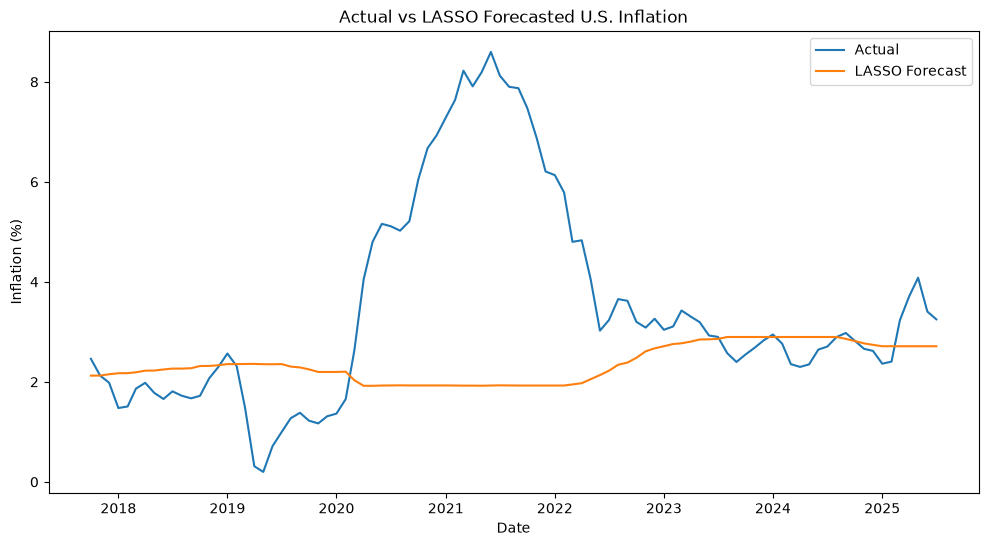

In [55]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual"
)

plt.plot(
    y_test.index,
    lasso_pred,
    label="LASSO Forecast"
)

plt.xlabel("Date")
plt.ylabel("Inflation (%)")
plt.title(
    "Actual vs LASSO Forecasted U.S. Inflation"
)

plt.legend()

plt.show()

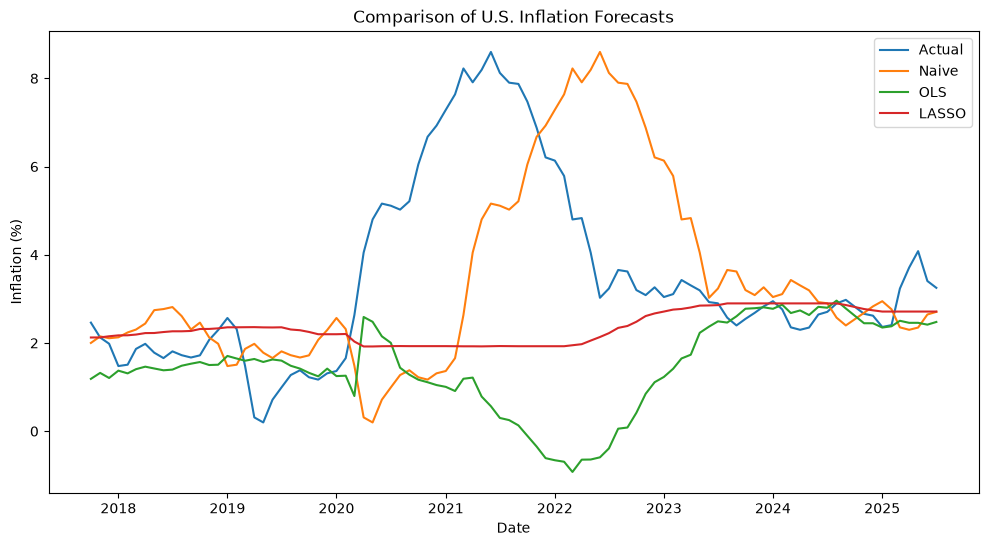

In [56]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual"
)

plt.plot(
    y_test.index,
    naive_pred,
    label="Naive"
)

plt.plot(
    y_test.index,
    ols_pred,
    label="OLS"
)

plt.plot(
    y_test.index,
    lasso_pred,
    label="LASSO"
)

plt.xlabel("Date")
plt.ylabel("Inflation (%)")
plt.title(
    "Comparison of U.S. Inflation Forecasts"
)

plt.legend()

plt.show()

**Plot the LASSO Coefficients**

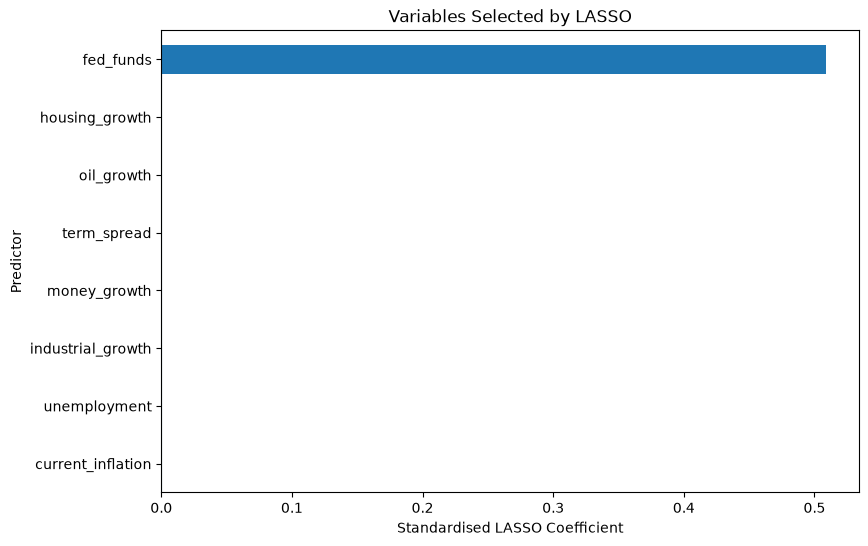

In [57]:
final_lasso_coefficients.sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Standardised LASSO Coefficient")
plt.ylabel("Predictor")
plt.title(
    "Variables Selected by LASSO"
)

plt.axvline(
    x=0
)

plt.show()

**Examine the LASSO Regularisation Path**

In [58]:
path_scaler = StandardScaler()

X_train_path = path_scaler.fit_transform(
    X_train
)

path_alphas = np.logspace(
    -4,
    1,
    100
)

coefficient_path = []

for alpha in path_alphas:
    
    model = Lasso(
        alpha=alpha,
        max_iter=100000
    )
    
    model.fit(
        X_train_path,
        y_train
    )
    
    coefficient_path.append(
        model.coef_
    )

coefficient_path = np.array(
    coefficient_path
)

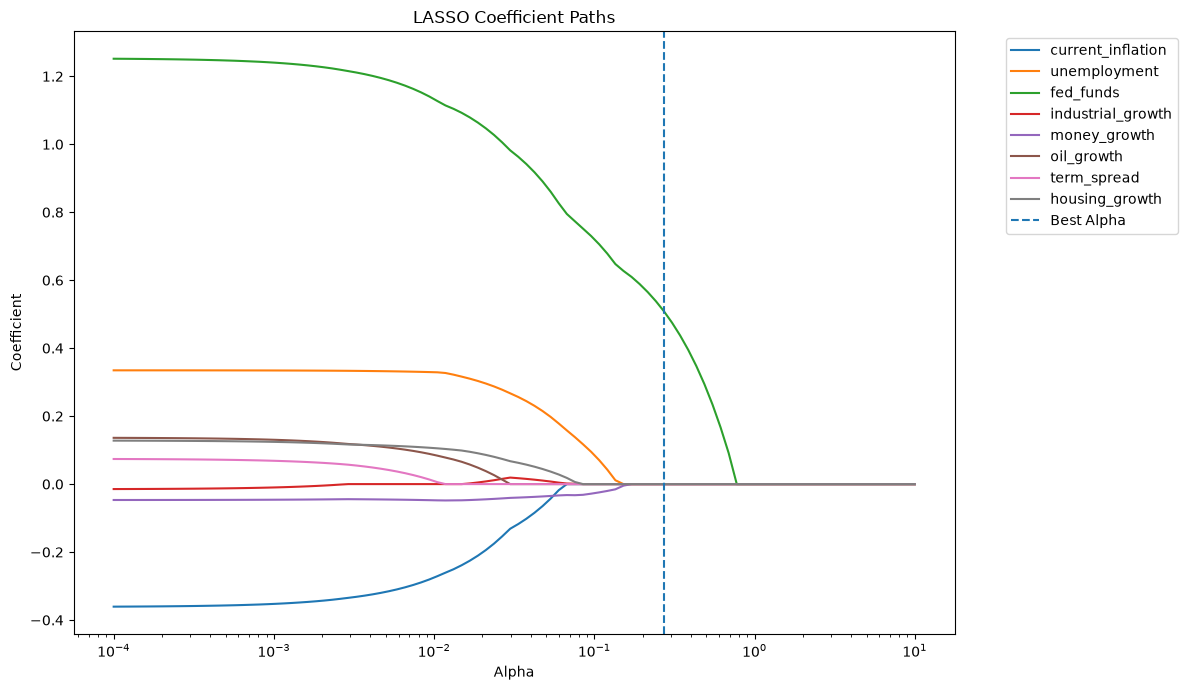

In [59]:
plt.figure(figsize=(12, 7))

for i, feature in enumerate(features):
    
    plt.semilogx(
        path_alphas,
        coefficient_path[:, i],
        label=feature
    )

plt.axvline(
    best_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.title(
    "LASSO Coefficient Paths"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

**Count How Many Variables Survive at Different Alpha Values**

In [60]:
selected_counts = []

for alpha in path_alphas:
    
    model = Lasso(
        alpha=alpha,
        max_iter=100000
    )
    
    model.fit(
        X_train_path,
        y_train
    )
    
    selected_counts.append(
        np.sum(model.coef_ != 0)
    )

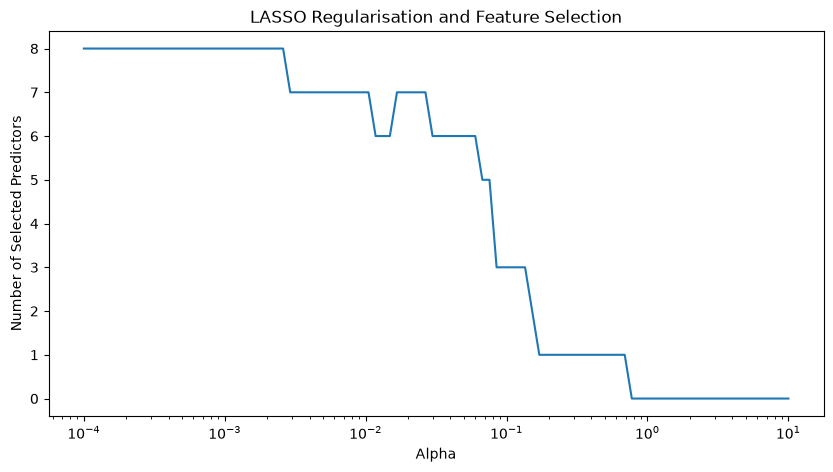

In [61]:
plt.figure(figsize=(10, 5))

plt.semilogx(
    path_alphas,
    selected_counts
)

plt.xlabel("Alpha")
plt.ylabel("Number of Selected Predictors")
plt.title(
    "LASSO Regularisation and Feature Selection"
)

plt.show()

**Residual Analysis**

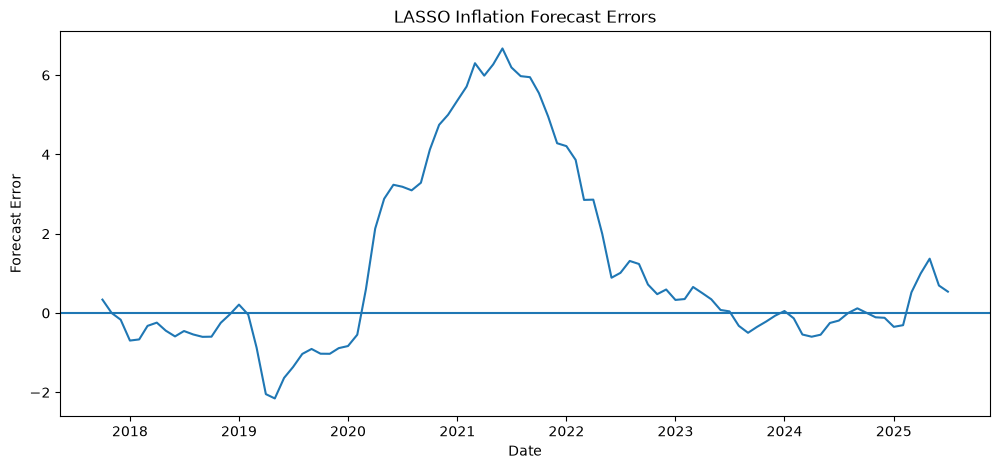

In [62]:
lasso_residuals = (
    y_test.values
    - lasso_pred
)

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    lasso_residuals
)

plt.axhline(
    y=0
)

plt.xlabel("Date")
plt.ylabel("Forecast Error")
plt.title(
    "LASSO Inflation Forecast Errors"
)

plt.show()

**Predicted vs Residual Plot**

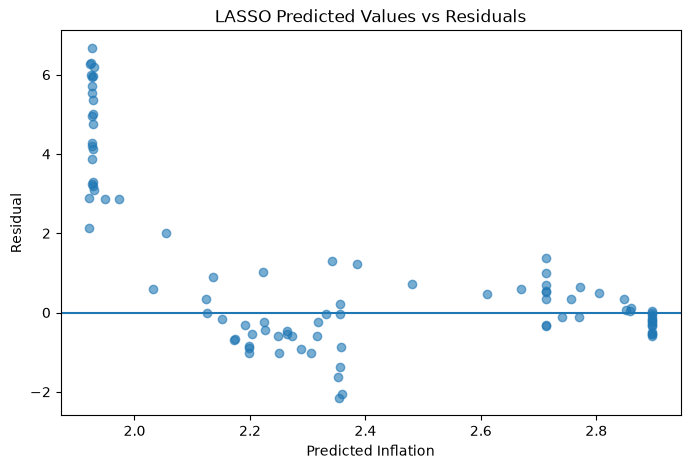

In [63]:
plt.figure(figsize=(8, 5))

plt.scatter(
    lasso_pred,
    lasso_residuals,
    alpha=0.6
)

plt.axhline(
    y=0
)

plt.xlabel("Predicted Inflation")
plt.ylabel("Residual")
plt.title(
    "LASSO Predicted Values vs Residuals"
)

plt.show()

In [64]:
forecast_results = pd.DataFrame({
    "Actual": y_test,
    "Naive": naive_pred,
    "OLS": ols_pred,
    "LASSO": lasso_pred
})

forecast_results.head(10).round(3)

,Actual,Naive,OLS,LASSO
DATE,,,,
2017-10-01,2.461,2.001,1.186,2.124
2017-11-01,2.125,2.149,1.322,2.126
2017-12-01,1.983,2.108,1.206,2.152
2018-01-01,1.477,2.129,1.373,2.172
2018-02-01,1.507,2.238,1.311,2.174
2018-03-01,1.866,2.304,1.406,2.191
2018-04-01,1.981,2.441,1.463,2.224
2018-05-01,1.780,2.744,1.422,2.226
2018-06-01,1.657,2.769,1.381,2.248


In [65]:
forecast_results.tail(10).round(3)

,Actual,Naive,OLS,LASSO
DATE,,,,
2024-09-01,2.978,2.398,2.782,2.860
2024-11-01,2.661,2.683,2.447,2.770
2024-12-01,2.619,2.830,2.447,2.740
2025-01-01,2.363,2.947,2.350,2.712
2025-02-01,2.405,2.763,2.379,2.712
2025-03-01,3.233,2.354,2.503,2.712
2025-04-01,3.710,2.299,2.457,2.712
2025-05-01,4.082,2.349,2.457,2.712
2025-06-01,3.405,2.645,2.415,2.712


In [66]:
performance.to_csv(
    "problem_11_model_performance.csv",
    index=False
)

final_coefficient_table.to_csv(
    "problem_11_coefficients.csv"
)

forecast_results.to_csv(
    "problem_11_forecasts.csv"
)

## END